PROJECT-SPECIFIC EDA

Dataset shape: (190, 26)

PROJECT SUMMARY
                           Metric         Value
0     Number of Building Projects  1.900000e+02
1        Average Planned Duration  5.547000e+02
2         Average Actual Duration  6.729859e+02
3      Average Schedule Delay (%)  2.135442e+01
4            Average Planned Cost  2.774772e+07
5             Average Actual Cost  3.308165e+07
6        Average Cost Overrun (%)  1.831897e+01
7                Delayed Projects  1.340000e+02
8            Non-Delayed Projects  5.600000e+01
9      Projects with Cost Overrun  1.240000e+02
10  Projects without Cost Overrun  6.600000e+01

SCHEDULE DELAY DISTRIBUTION
  Schedule_Delay  Number_of_Projects  Percentage
0            Yes                 134   70.526316
1             No                  56   29.473684

COST OVERRUN DISTRIBUTION
  Cost_Overrun  Number_of_Projects  Percentage
0          Yes                 124   65.263158
1           No                  66   34.736842


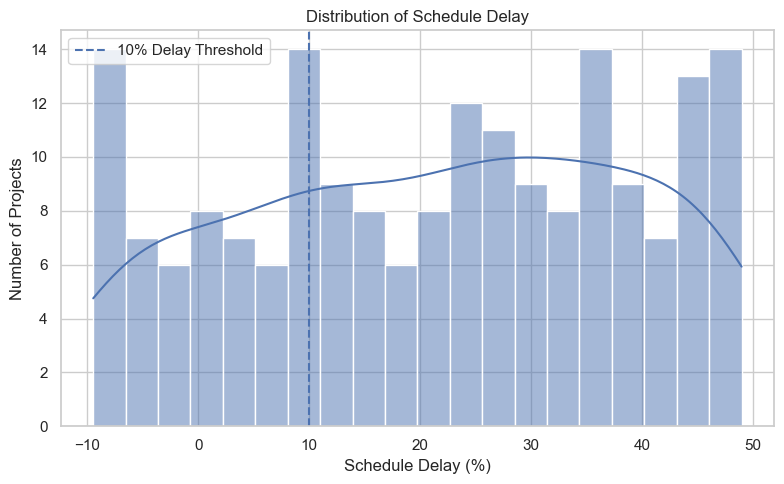

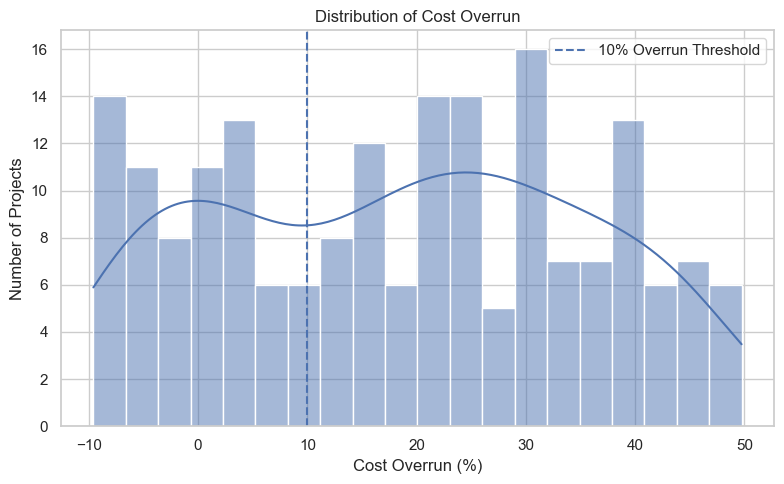

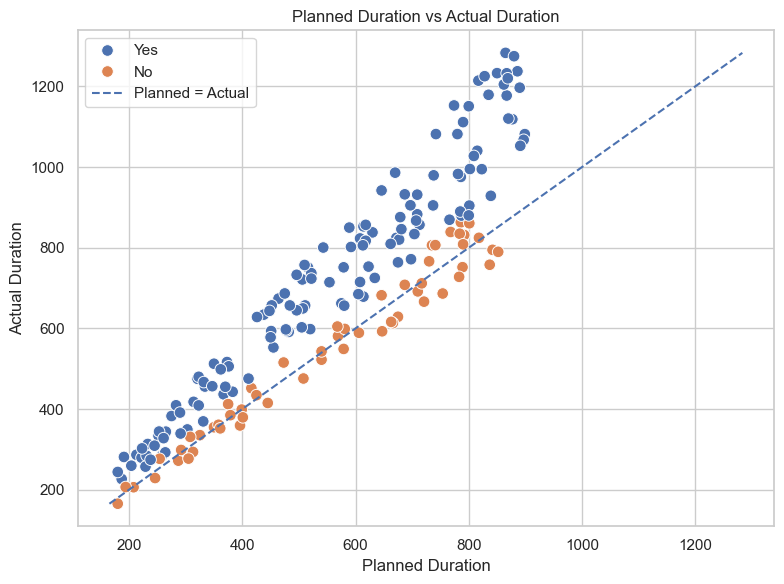

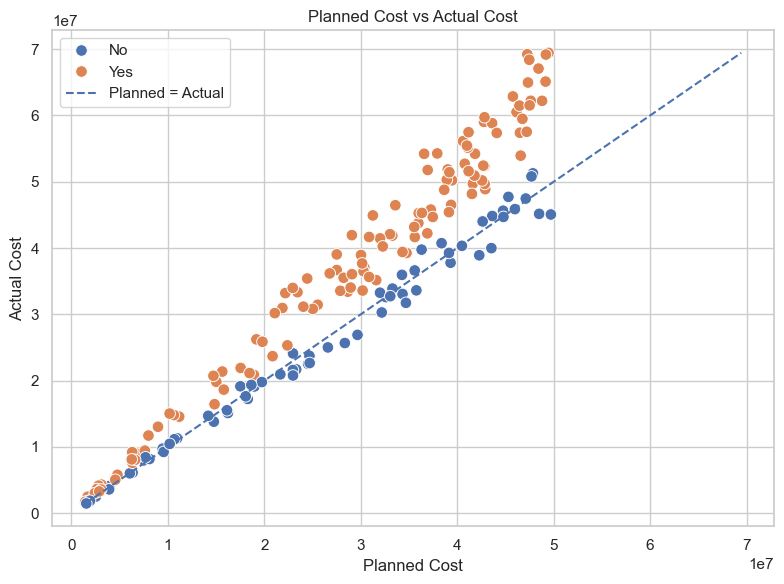

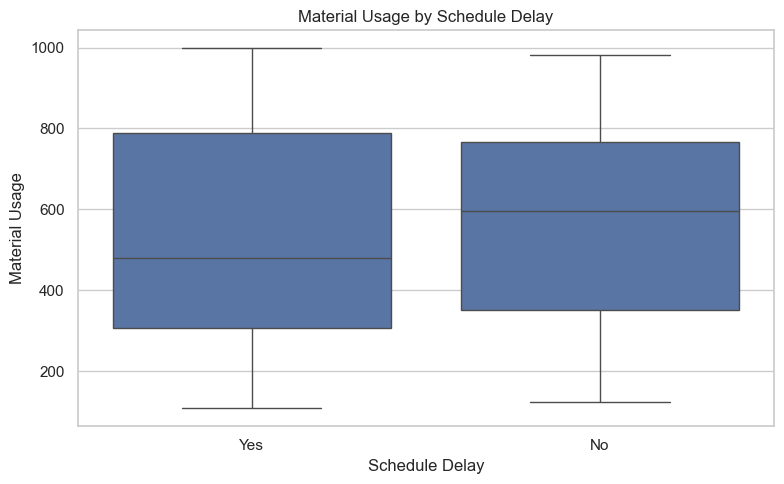

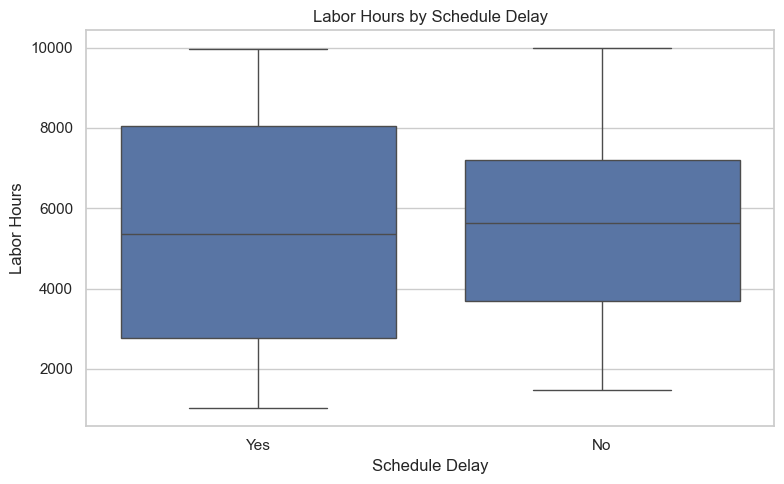

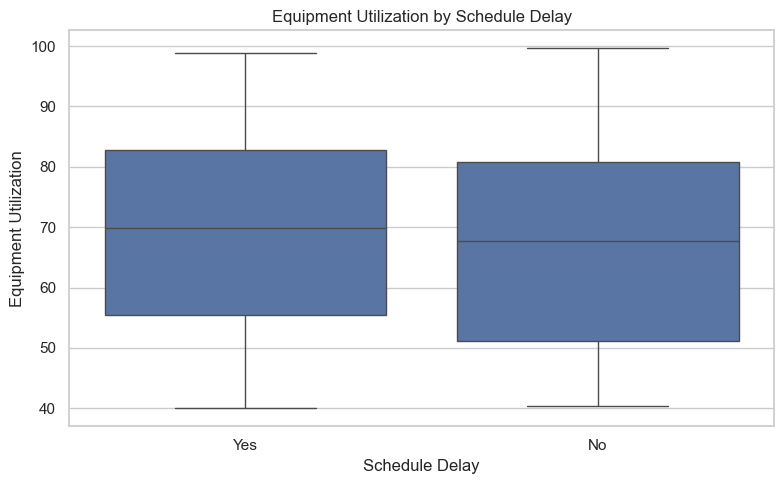

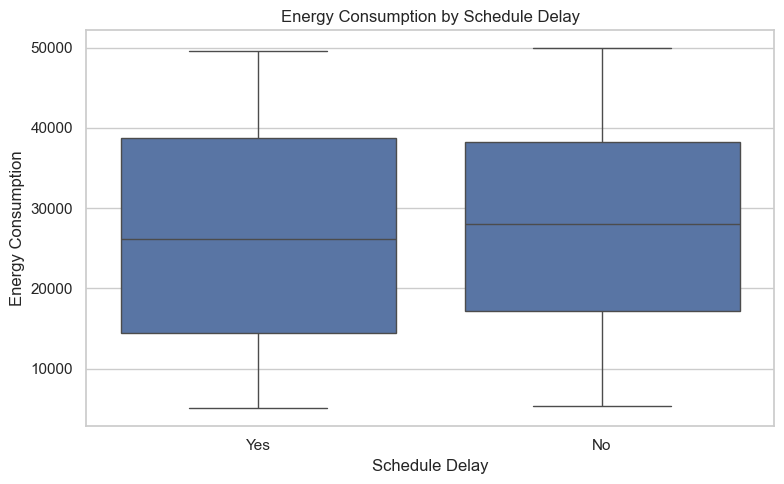

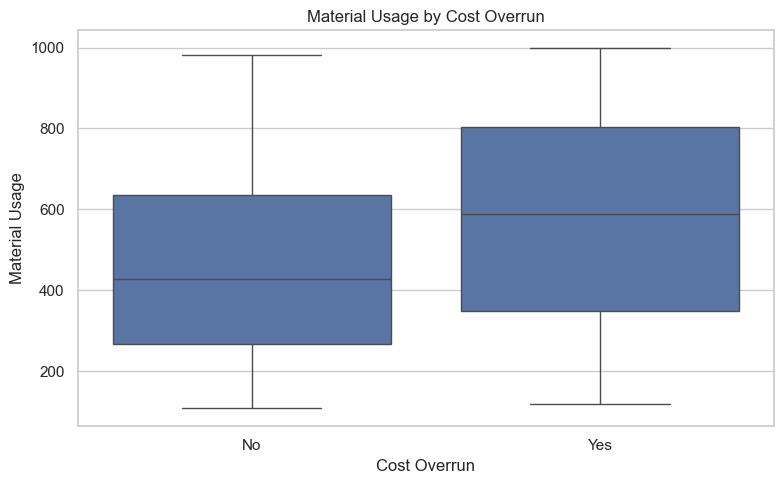

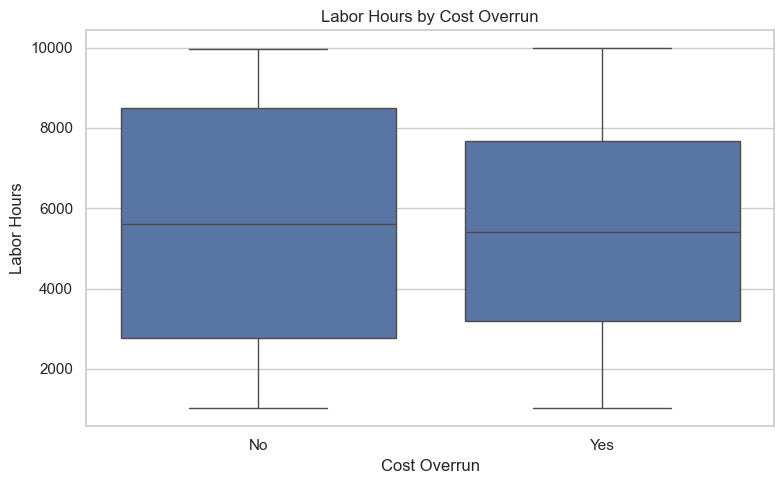

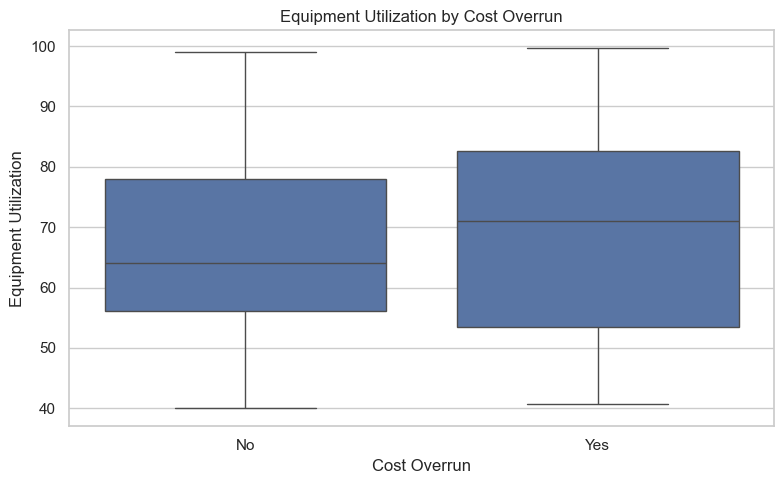

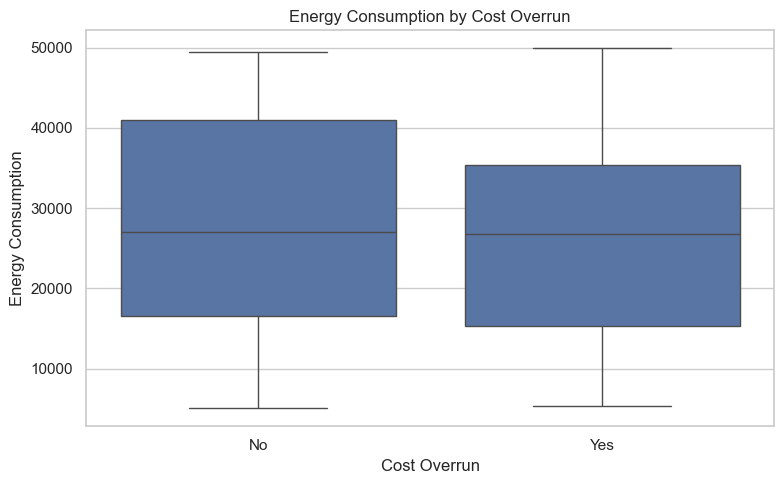

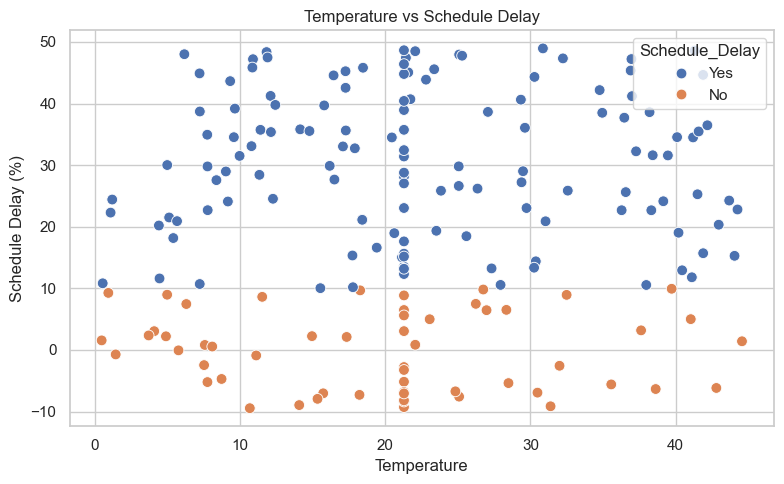

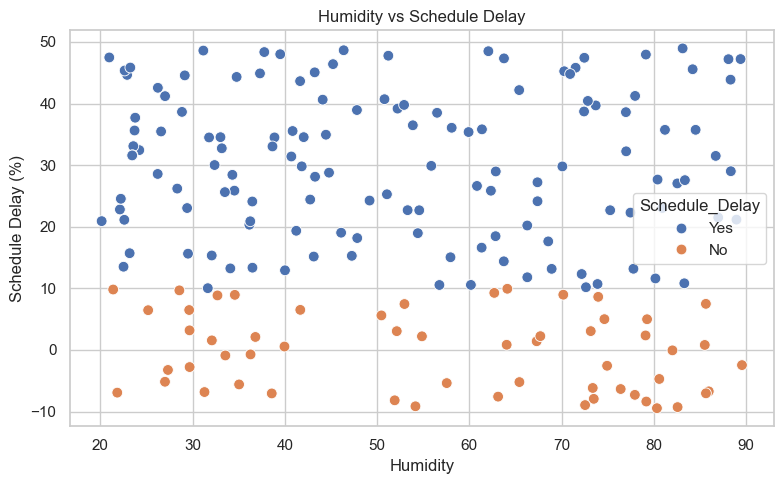

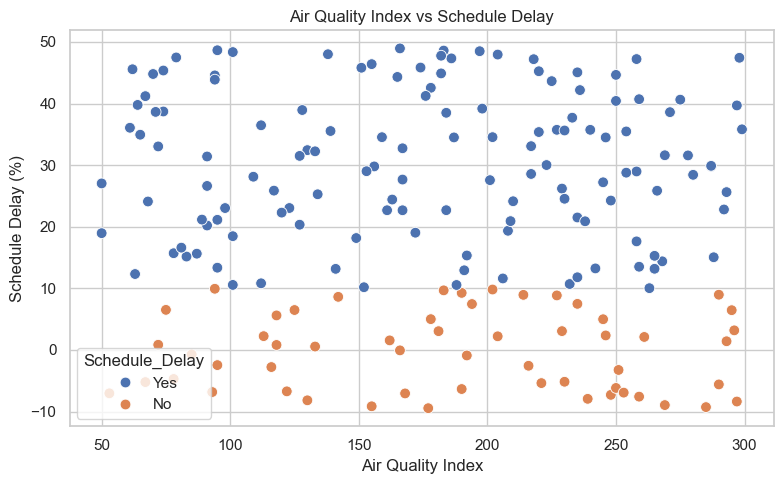

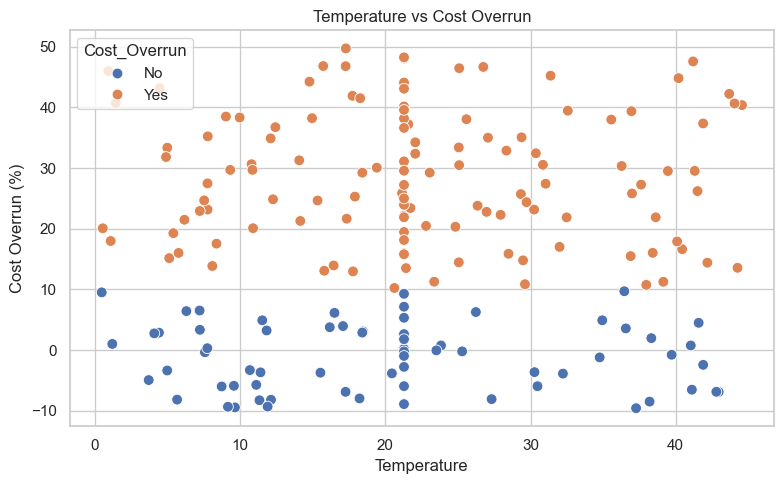

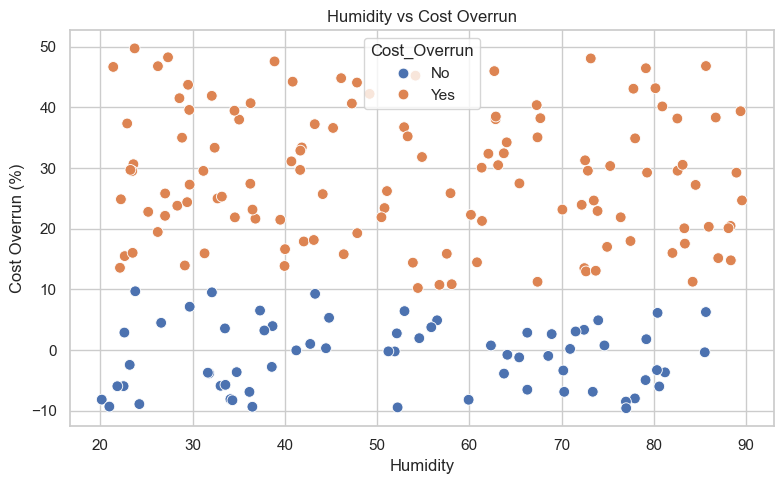

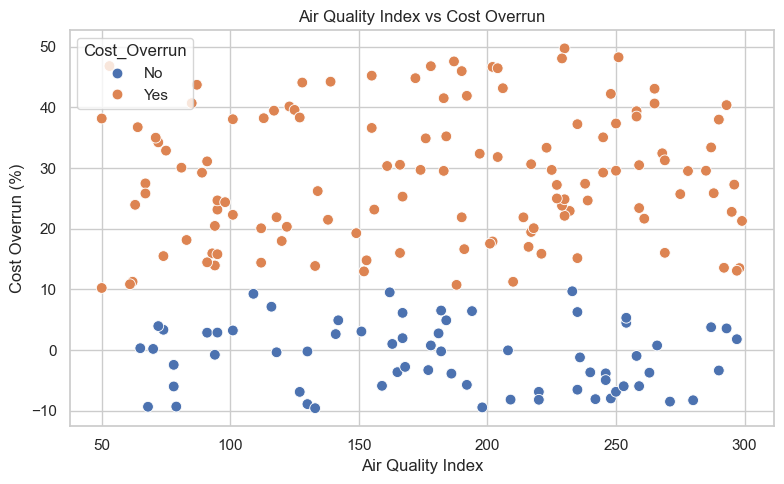


WEATHER VS SCHEDULE DELAY (%)
Schedule_Delay            No        Yes
Weather_Condition                      
Cloudy             32.352941  67.647059
Rainy              25.581395  74.418605
Snowy              37.931034  62.068966
Stormy             26.530612  73.469388
Sunny              28.571429  71.428571


<Figure size 900x500 with 0 Axes>

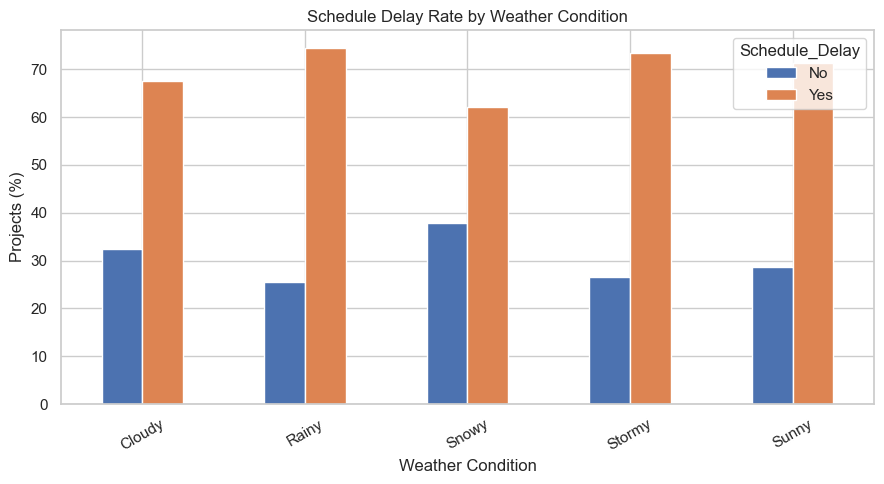


WEATHER VS COST OVERRUN (%)
Cost_Overrun              No        Yes
Weather_Condition                      
Cloudy             29.411765  70.588235
Rainy              27.906977  72.093023
Snowy              31.034483  68.965517
Stormy             42.857143  57.142857
Sunny              40.000000  60.000000


<Figure size 900x500 with 0 Axes>

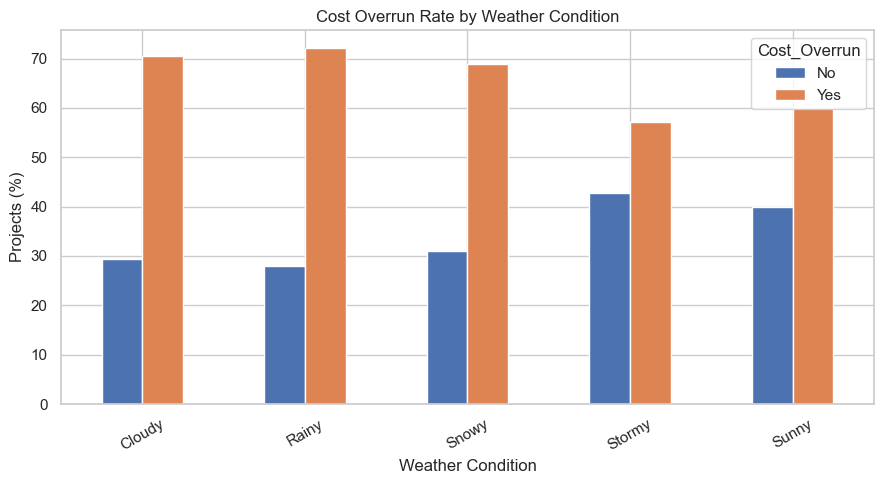

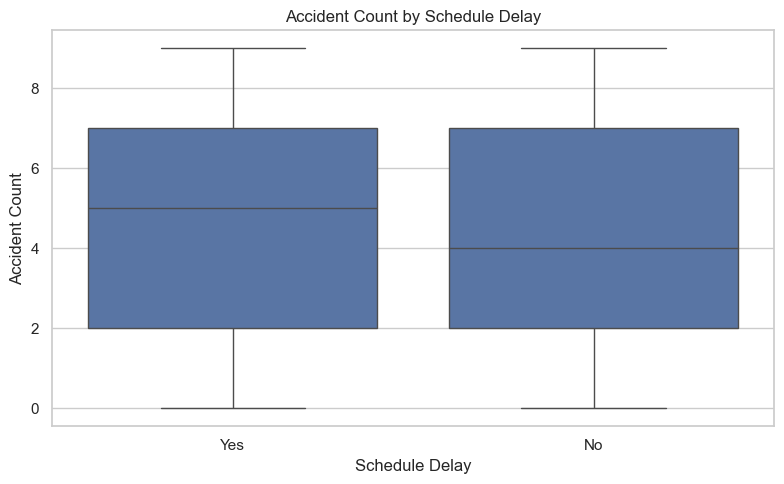

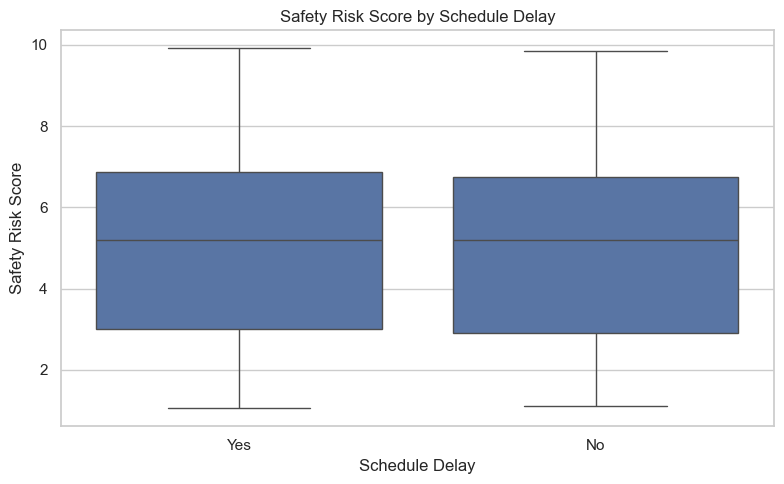

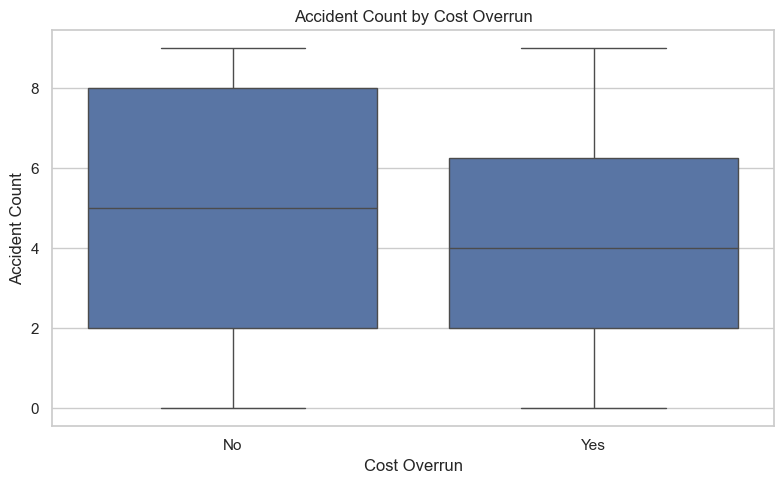

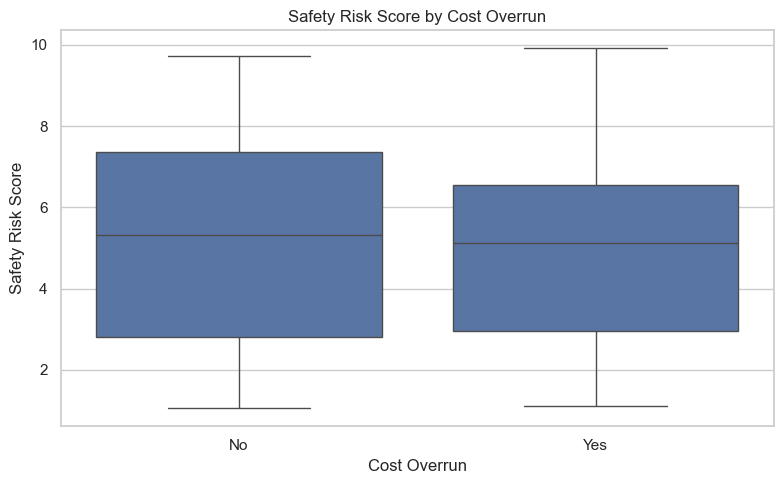

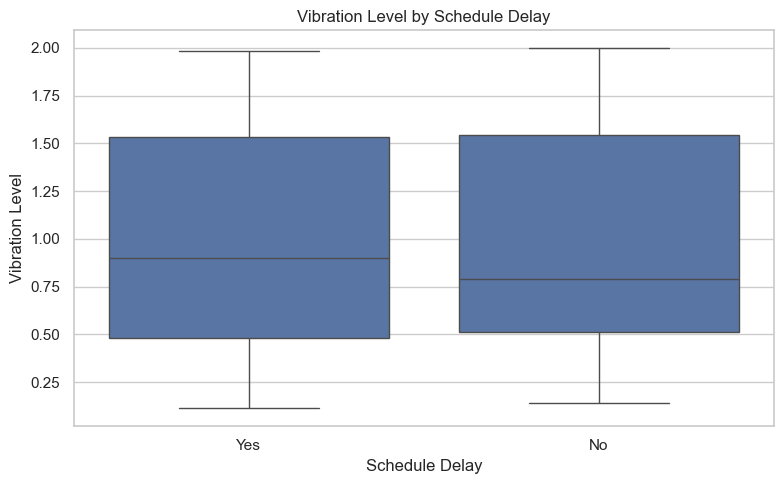

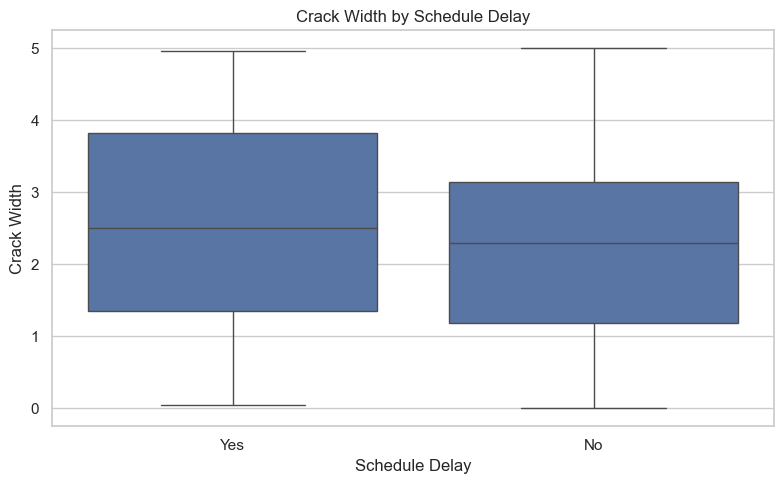

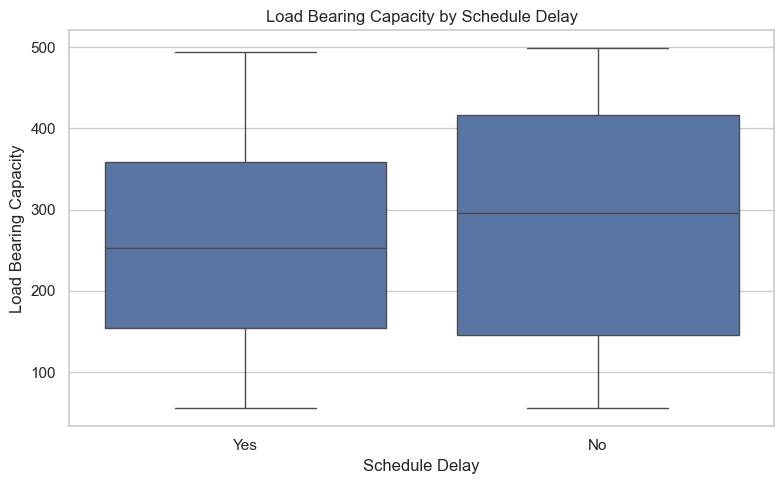

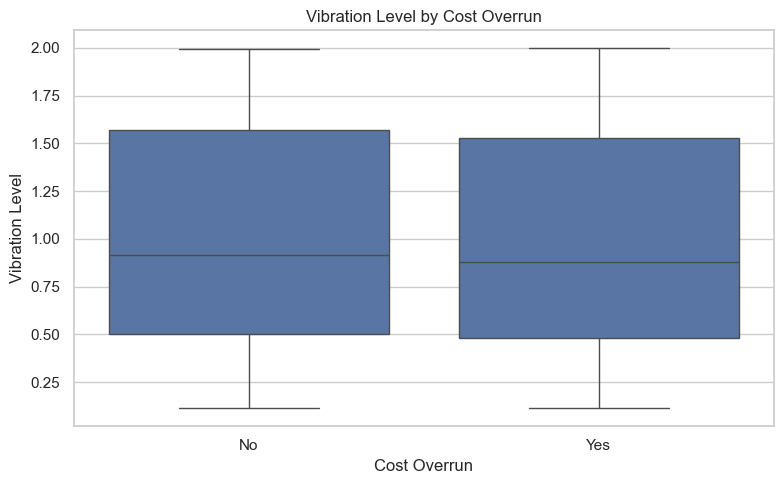

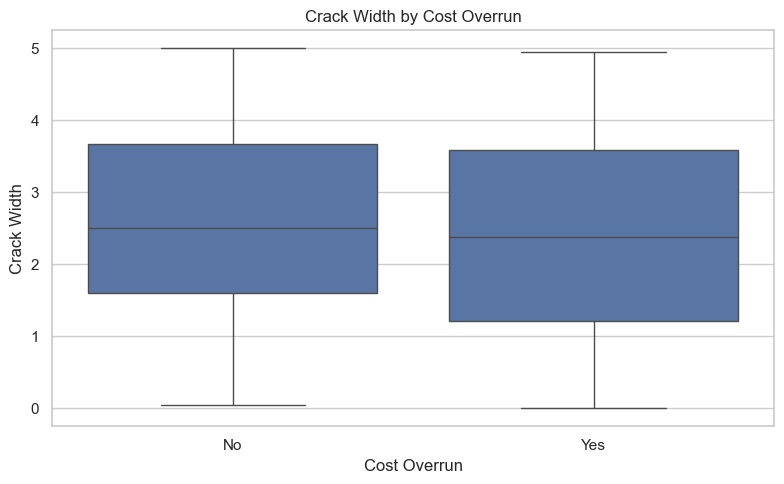

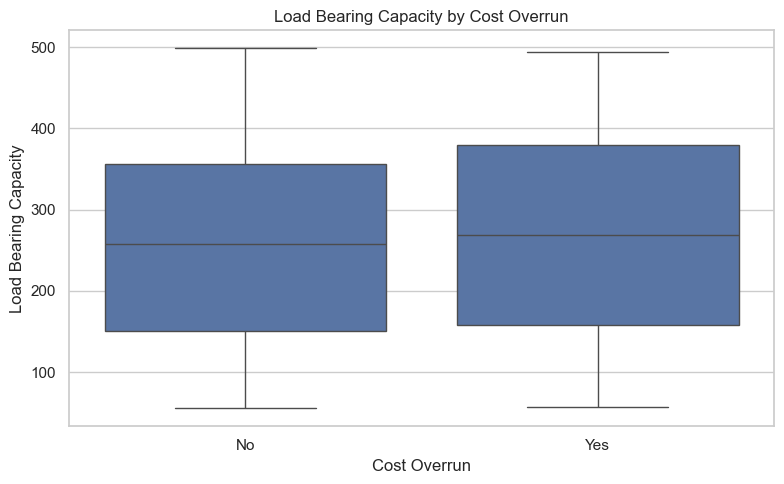

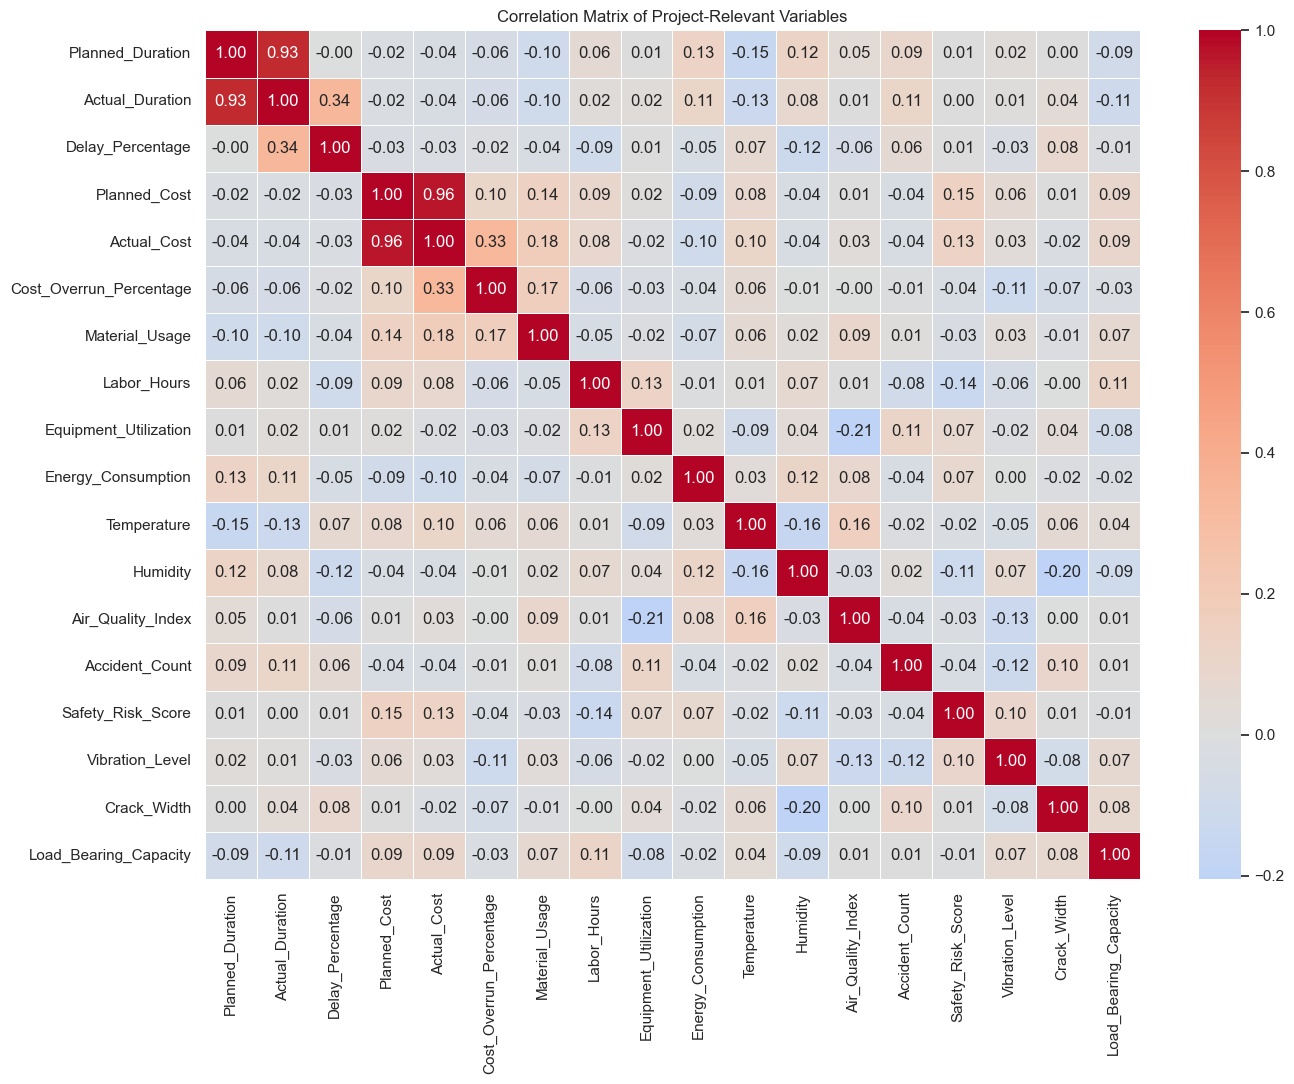


CORRELATION WITH SCHEDULE DELAY
Delay_Percentage           1.000000
Actual_Duration            0.342035
Crack_Width                0.083179
Temperature                0.071111
Accident_Count             0.061105
Equipment_Utilization      0.010496
Safety_Risk_Score          0.006397
Planned_Duration          -0.004527
Load_Bearing_Capacity     -0.014549
Cost_Overrun_Percentage   -0.020689
Actual_Cost               -0.030855
Planned_Cost              -0.033042
Vibration_Level           -0.034036
Material_Usage            -0.039321
Energy_Consumption        -0.049656
Air_Quality_Index         -0.061865
Labor_Hours               -0.094182
Humidity                  -0.122478
Name: Delay_Percentage, dtype: float64

CORRELATION WITH COST OVERRUN
Cost_Overrun_Percentage    1.000000
Actual_Cost                0.332354
Material_Usage             0.166817
Planned_Cost               0.101090
Temperature                0.058841
Air_Quality_Index         -0.000376
Humidity                  -0.0052

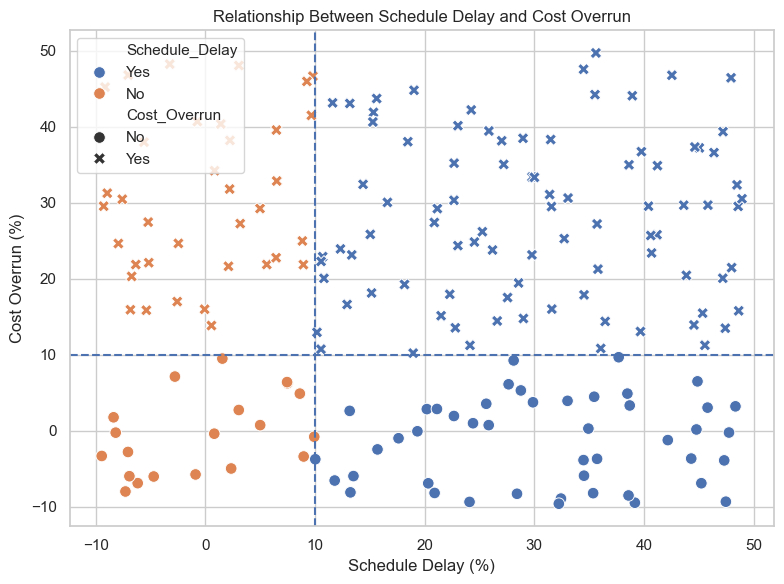


PROJECT OUTCOME COMBINATION
           Project_Outcome  Number_of_Projects  Percentage
0     Delay + Cost Overrun                  88   46.315789
1               Delay Only                  46   24.210526
2        Cost Overrun Only                  36   18.947368
3  On Schedule + On Budget                  20   10.526316


PROJECT-SPECIFIC EDA COMPLETED

The EDA has focused ONLY on variables relevant to:
1. Schedule delay
2. Cost overrun
3. Construction resources
4. Safety and project risk
5. Environmental conditions
6. Building/site conditions
7. Relationship between delay and cost overrun

EDA results saved in:
e:\Construction_Analysis_Project\Data\EDA_Results

Next stage:
Feature Selection + Feature Engineering → ML preprocessing → Model Training → Model Comparison → Probability Prediction → SHAP


In [3]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")


# ============================================================
# 2. SETTINGS
# ============================================================

INPUT_FILE = "building_final_processed_data.csv"

OUTPUT_FOLDER = "EDA_Results"

os.makedirs(
    OUTPUT_FOLDER,
    exist_ok=True
)

sns.set_theme(
    style="whitegrid"
)

DPI = 300


# ============================================================
# 3. LOAD PROCESSED DATA
# ============================================================

df = pd.read_csv(
    INPUT_FILE
)


print("=" * 70)
print("PROJECT-SPECIFIC EDA")
print("=" * 70)

print(
    "\nDataset shape:",
    df.shape
)


# ============================================================
# 4. PROJECT-RELEVANT VARIABLES
# ============================================================

# -----------------------------
# Schedule-related variables
# -----------------------------

schedule_variables = [

    "Planned_Duration",
    "Actual_Duration",
    "Delay_Percentage"

]


# -----------------------------
# Cost-related variables
# -----------------------------

cost_variables = [

    "Planned_Cost",
    "Actual_Cost",
    "Cost_Overrun_Percentage"

]


# -----------------------------
# Construction/resource factors
# -----------------------------

construction_factors = [

    "Material_Usage",
    "Labor_Hours",
    "Equipment_Utilization",

    "Energy_Consumption"

]


# -----------------------------
# Safety/site/environment factors
# -----------------------------

risk_environment_factors = [

    "Accident_Count",
    "Safety_Risk_Score",

    "Weather_Condition",
    "Temperature",
    "Humidity",
    "Air_Quality_Index",

    "Vibration_Level",
    "Crack_Width",
    "Load_Bearing_Capacity"

]


# -----------------------------
# Target variables
# -----------------------------

target_variables = [

    "Schedule_Delay",
    "Cost_Overrun"

]


# ============================================================
# 5. CHECK REQUIRED VARIABLES
# ============================================================

required_for_eda = (

    schedule_variables
    +
    cost_variables
    +
    construction_factors
    +
    risk_environment_factors
    +
    target_variables

)


missing_variables = [

    column
    for column in required_for_eda
    if column not in df.columns

]


if missing_variables:

    raise ValueError(

        "The following required variables "
        "are missing from the processed dataset:\n"
        +
        "\n".join(missing_variables)

    )


# ============================================================
# 6. BASIC PROJECT SUMMARY
# ============================================================

project_summary = pd.DataFrame({

    "Metric": [

        "Number of Building Projects",

        "Average Planned Duration",

        "Average Actual Duration",

        "Average Schedule Delay (%)",

        "Average Planned Cost",

        "Average Actual Cost",

        "Average Cost Overrun (%)",

        "Delayed Projects",

        "Non-Delayed Projects",

        "Projects with Cost Overrun",

        "Projects without Cost Overrun"

    ],

    "Value": [

        len(df),

        df["Planned_Duration"].mean(),

        df["Actual_Duration"].mean(),

        df["Delay_Percentage"].mean(),

        df["Planned_Cost"].mean(),

        df["Actual_Cost"].mean(),

        df["Cost_Overrun_Percentage"].mean(),

        (df["Schedule_Delay"] == "Yes").sum(),

        (df["Schedule_Delay"] == "No").sum(),

        (df["Cost_Overrun"] == "Yes").sum(),

        (df["Cost_Overrun"] == "No").sum()

    ]

})


print("\nPROJECT SUMMARY")
print(project_summary)


project_summary.to_csv(

    os.path.join(
        OUTPUT_FOLDER,
        "01_project_summary.csv"
    ),

    index=False

)


# ============================================================
# 7. TARGET DISTRIBUTION
# ============================================================

# ------------------------------------------------------------
# Schedule Delay
# ------------------------------------------------------------

schedule_distribution = (

    df["Schedule_Delay"]
    .value_counts()
    .reset_index()

)

schedule_distribution.columns = [

    "Schedule_Delay",
    "Number_of_Projects"

]


schedule_distribution[
    "Percentage"
] = (

    schedule_distribution[
        "Number_of_Projects"
    ]

    /

    len(df)

    *

    100

)


print("\nSCHEDULE DELAY DISTRIBUTION")
print(schedule_distribution)


schedule_distribution.to_csv(

    os.path.join(
        OUTPUT_FOLDER,
        "02_schedule_delay_distribution.csv"
    ),

    index=False

)


# ------------------------------------------------------------
# Cost Overrun
# ------------------------------------------------------------

cost_distribution = (

    df["Cost_Overrun"]
    .value_counts()
    .reset_index()

)

cost_distribution.columns = [

    "Cost_Overrun",
    "Number_of_Projects"

]


cost_distribution[
    "Percentage"
] = (

    cost_distribution[
        "Number_of_Projects"
    ]

    /

    len(df)

    *

    100

)


print("\nCOST OVERRUN DISTRIBUTION")
print(cost_distribution)


cost_distribution.to_csv(

    os.path.join(
        OUTPUT_FOLDER,
        "03_cost_overrun_distribution.csv"
    ),

    index=False

)


# ============================================================
# 8. SCHEDULE DELAY DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(8, 5)
)

sns.histplot(

    data=df,

    x="Delay_Percentage",

    bins=20,

    kde=True

)

plt.axvline(

    10,

    linestyle="--",

    label="10% Delay Threshold"

)

plt.title(
    "Distribution of Schedule Delay"
)

plt.xlabel(
    "Schedule Delay (%)"
)

plt.ylabel(
    "Number of Projects"
)

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_FOLDER,

        "04_schedule_delay_distribution.png"

    ),

    dpi=DPI

)

plt.show()


# ============================================================
# 9. COST OVERRUN DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(8, 5)
)

sns.histplot(

    data=df,

    x="Cost_Overrun_Percentage",

    bins=20,

    kde=True

)

plt.axvline(

    10,

    linestyle="--",

    label="10% Overrun Threshold"

)

plt.title(
    "Distribution of Cost Overrun"
)

plt.xlabel(
    "Cost Overrun (%)"
)

plt.ylabel(
    "Number of Projects"
)

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_FOLDER,

        "05_cost_overrun_distribution.png"

    ),

    dpi=DPI

)

plt.show()


# ============================================================
# 10. PLANNED VS ACTUAL DURATION
# ============================================================

plt.figure(
    figsize=(8, 6)
)

sns.scatterplot(

    data=df,

    x="Planned_Duration",

    y="Actual_Duration",

    hue="Schedule_Delay",

    s=70

)


min_value = min(

    df["Planned_Duration"].min(),

    df["Actual_Duration"].min()

)


max_value = max(

    df["Planned_Duration"].max(),

    df["Actual_Duration"].max()

)


plt.plot(

    [min_value, max_value],

    [min_value, max_value],

    linestyle="--",

    label="Planned = Actual"

)


plt.title(
    "Planned Duration vs Actual Duration"
)

plt.xlabel(
    "Planned Duration"
)

plt.ylabel(
    "Actual Duration"
)

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_FOLDER,

        "06_planned_vs_actual_duration.png"

    ),

    dpi=DPI

)

plt.show()


# ============================================================
# 11. PLANNED VS ACTUAL COST
# ============================================================

plt.figure(
    figsize=(8, 6)
)

sns.scatterplot(

    data=df,

    x="Planned_Cost",

    y="Actual_Cost",

    hue="Cost_Overrun",

    s=70

)


min_value = min(

    df["Planned_Cost"].min(),

    df["Actual_Cost"].min()

)


max_value = max(

    df["Planned_Cost"].max(),

    df["Actual_Cost"].max()

)


plt.plot(

    [min_value, max_value],

    [min_value, max_value],

    linestyle="--",

    label="Planned = Actual"

)


plt.title(
    "Planned Cost vs Actual Cost"
)

plt.xlabel(
    "Planned Cost"
)

plt.ylabel(
    "Actual Cost"
)

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_FOLDER,

        "07_planned_vs_actual_cost.png"

    ),

    dpi=DPI

)

plt.show()


# ============================================================
# 12. DELAY BY CONSTRUCTION FACTORS
# ============================================================

for feature in construction_factors:

    plt.figure(
        figsize=(8, 5)
    )

    sns.boxplot(

        data=df,

        x="Schedule_Delay",

        y=feature

    )

    plt.title(

        f"{feature.replace('_', ' ')} "
        "by Schedule Delay"

    )

    plt.xlabel(
        "Schedule Delay"
    )

    plt.ylabel(
        feature.replace("_", " ")
    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            OUTPUT_FOLDER,

            f"08_delay_{feature}.png"

        ),

        dpi=DPI

    )

    plt.show()


# ============================================================
# 13. COST OVERRUN BY CONSTRUCTION FACTORS
# ============================================================

for feature in construction_factors:

    plt.figure(
        figsize=(8, 5)
    )

    sns.boxplot(

        data=df,

        x="Cost_Overrun",

        y=feature

    )

    plt.title(

        f"{feature.replace('_', ' ')} "
        "by Cost Overrun"

    )

    plt.xlabel(
        "Cost Overrun"
    )

    plt.ylabel(
        feature.replace("_", " ")
    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            OUTPUT_FOLDER,

            f"09_overrun_{feature}.png"

        ),

        dpi=DPI

    )

    plt.show()


# ============================================================
# 14. ENVIRONMENTAL FACTORS VS SCHEDULE DELAY
# ============================================================

environmental_numeric = [

    "Temperature",
    "Humidity",
    "Air_Quality_Index"

]


for feature in environmental_numeric:

    plt.figure(
        figsize=(8, 5)
    )

    sns.scatterplot(

        data=df,

        x=feature,

        y="Delay_Percentage",

        hue="Schedule_Delay",

        s=60

    )

    plt.title(

        f"{feature.replace('_', ' ')} "
        "vs Schedule Delay"

    )

    plt.xlabel(
        feature.replace("_", " ")
    )

    plt.ylabel(
        "Schedule Delay (%)"
    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            OUTPUT_FOLDER,

            f"10_delay_environment_{feature}.png"

        ),

        dpi=DPI

    )

    plt.show()


# ============================================================
# 15. ENVIRONMENTAL FACTORS VS COST OVERRUN
# ============================================================

for feature in environmental_numeric:

    plt.figure(
        figsize=(8, 5)
    )

    sns.scatterplot(

        data=df,

        x=feature,

        y="Cost_Overrun_Percentage",

        hue="Cost_Overrun",

        s=60

    )

    plt.title(

        f"{feature.replace('_', ' ')} "
        "vs Cost Overrun"

    )

    plt.xlabel(
        feature.replace("_", " ")
    )

    plt.ylabel(
        "Cost Overrun (%)"
    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            OUTPUT_FOLDER,

            f"11_overrun_environment_{feature}.png"

        ),

        dpi=DPI

    )

    plt.show()


# ============================================================
# 16. WEATHER VS SCHEDULE DELAY
# ============================================================

weather_delay = (

    pd.crosstab(

        df["Weather_Condition"],

        df["Schedule_Delay"],

        normalize="index"

    )

    * 100

)


print(
    "\nWEATHER VS SCHEDULE DELAY (%)"
)

print(
    weather_delay
)


weather_delay.to_csv(

    os.path.join(

        OUTPUT_FOLDER,

        "12_weather_vs_schedule_delay.csv"

    )

)


plt.figure(
    figsize=(9, 5)
)

weather_delay.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Schedule Delay Rate by Weather Condition"
)

plt.xlabel(
    "Weather Condition"
)

plt.ylabel(
    "Projects (%)"
)

plt.xticks(
    rotation=30
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_FOLDER,

        "13_weather_vs_schedule_delay.png"

    ),

    dpi=DPI

)

plt.show()


# ============================================================
# 17. WEATHER VS COST OVERRUN
# ============================================================

weather_cost = (

    pd.crosstab(

        df["Weather_Condition"],

        df["Cost_Overrun"],

        normalize="index"

    )

    * 100

)


print(
    "\nWEATHER VS COST OVERRUN (%)"
)

print(
    weather_cost
)


weather_cost.to_csv(

    os.path.join(

        OUTPUT_FOLDER,

        "14_weather_vs_cost_overrun.csv"

    )

)


plt.figure(
    figsize=(9, 5)
)

weather_cost.plot(

    kind="bar",

    figsize=(9, 5)

)

plt.title(
    "Cost Overrun Rate by Weather Condition"
)

plt.xlabel(
    "Weather Condition"
)

plt.ylabel(
    "Projects (%)"
)

plt.xticks(
    rotation=30
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_FOLDER,

        "15_weather_vs_cost_overrun.png"

    ),

    dpi=DPI

)

plt.show()


# ============================================================
# 18. SAFETY FACTORS VS SCHEDULE DELAY
# ============================================================

safety_features = [

    "Accident_Count",
    "Safety_Risk_Score"

]


for feature in safety_features:

    plt.figure(
        figsize=(8, 5)
    )

    sns.boxplot(

        data=df,

        x="Schedule_Delay",

        y=feature

    )

    plt.title(

        f"{feature.replace('_', ' ')} "
        "by Schedule Delay"

    )

    plt.xlabel(
        "Schedule Delay"
    )

    plt.ylabel(
        feature.replace("_", " ")
    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            OUTPUT_FOLDER,

            f"16_safety_delay_{feature}.png"

        ),

        dpi=DPI

    )

    plt.show()


# ============================================================
# 19. SAFETY FACTORS VS COST OVERRUN
# ============================================================

for feature in safety_features:

    plt.figure(
        figsize=(8, 5)
    )

    sns.boxplot(

        data=df,

        x="Cost_Overrun",

        y=feature

    )

    plt.title(

        f"{feature.replace('_', ' ')} "
        "by Cost Overrun"

    )

    plt.xlabel(
        "Cost Overrun"
    )

    plt.ylabel(
        feature.replace("_", " ")
    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            OUTPUT_FOLDER,

            f"17_safety_overrun_{feature}.png"

        ),

        dpi=DPI

    )

    plt.show()


# ============================================================
# 20. BUILDING/SITE CONDITION VS DELAY
# ============================================================

site_condition_features = [

    "Vibration_Level",
    "Crack_Width",
    "Load_Bearing_Capacity"

]


for feature in site_condition_features:

    plt.figure(
        figsize=(8, 5)
    )

    sns.boxplot(

        data=df,

        x="Schedule_Delay",

        y=feature

    )

    plt.title(

        f"{feature.replace('_', ' ')} "
        "by Schedule Delay"

    )

    plt.xlabel(
        "Schedule Delay"
    )

    plt.ylabel(
        feature.replace("_", " ")
    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            OUTPUT_FOLDER,

            f"18_site_condition_delay_{feature}.png"

        ),

        dpi=DPI

    )

    plt.show()


# ============================================================
# 21. BUILDING/SITE CONDITION VS COST OVERRUN
# ============================================================

for feature in site_condition_features:

    plt.figure(
        figsize=(8, 5)
    )

    sns.boxplot(

        data=df,

        x="Cost_Overrun",

        y=feature

    )

    plt.title(

        f"{feature.replace('_', ' ')} "
        "by Cost Overrun"

    )

    plt.xlabel(
        "Cost Overrun"
    )

    plt.ylabel(
        feature.replace("_", " ")
    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            OUTPUT_FOLDER,

            f"19_site_condition_overrun_{feature}.png"

        ),

        dpi=DPI

    )

    plt.show()


# ============================================================
# 22. CORRELATION ANALYSIS
# ============================================================

correlation_variables = (

    [

        "Planned_Duration",
        "Actual_Duration",
        "Delay_Percentage",

        "Planned_Cost",
        "Actual_Cost",
        "Cost_Overrun_Percentage",

        "Material_Usage",
        "Labor_Hours",
        "Equipment_Utilization",

        "Energy_Consumption",

        "Temperature",
        "Humidity",
        "Air_Quality_Index",

        "Accident_Count",
        "Safety_Risk_Score",

        "Vibration_Level",
        "Crack_Width",
        "Load_Bearing_Capacity"

    ]

)


correlation_matrix = (

    df[
        correlation_variables
    ]

    .corr()

)


correlation_matrix.to_csv(

    os.path.join(

        OUTPUT_FOLDER,

        "20_project_correlation_matrix.csv"

    )

)


plt.figure(
    figsize=(14, 11)
)

sns.heatmap(

    correlation_matrix,

    annot=True,

    fmt=".2f",

    cmap="coolwarm",

    center=0,

    linewidths=0.5

)

plt.title(
    "Correlation Matrix of Project-Relevant Variables"
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_FOLDER,

        "21_project_correlation_heatmap.png"

    ),

    dpi=DPI

)

plt.show()


# ============================================================
# 23. CORRELATION WITH SCHEDULE DELAY
# ============================================================

delay_correlation = (

    correlation_matrix[
        "Delay_Percentage"
    ]

    .sort_values(
        ascending=False
    )

)


print(
    "\n" + "=" * 70
)

print(
    "CORRELATION WITH SCHEDULE DELAY"
)

print(
    "=" * 70
)

print(
    delay_correlation
)


delay_correlation.to_csv(

    os.path.join(

        OUTPUT_FOLDER,

        "22_correlation_with_schedule_delay.csv"

    )

)


# ============================================================
# 24. CORRELATION WITH COST OVERRUN
# ============================================================

cost_correlation = (

    correlation_matrix[
        "Cost_Overrun_Percentage"
    ]

    .sort_values(
        ascending=False
    )

)


print(
    "\n" + "=" * 70
)

print(
    "CORRELATION WITH COST OVERRUN"
)

print(
    "=" * 70
)

print(
    cost_correlation
)


cost_correlation.to_csv(

    os.path.join(

        OUTPUT_FOLDER,

        "23_correlation_with_cost_overrun.csv"

    )

)


# ============================================================
# 25. DELAY VS COST OVERRUN RELATIONSHIP
# ============================================================

plt.figure(
    figsize=(8, 6)
)

sns.scatterplot(

    data=df,

    x="Delay_Percentage",

    y="Cost_Overrun_Percentage",

    hue="Schedule_Delay",

    style="Cost_Overrun",

    s=70

)

plt.axvline(

    10,

    linestyle="--"

)

plt.axhline(

    10,

    linestyle="--"

)

plt.title(
    "Relationship Between Schedule Delay and Cost Overrun"
)

plt.xlabel(
    "Schedule Delay (%)"
)

plt.ylabel(
    "Cost Overrun (%)"
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_FOLDER,

        "24_delay_vs_cost_overrun.png"

    ),

    dpi=DPI

)

plt.show()


# ============================================================
# 26. DELAY + COST OVERRUN COMBINATION
# ============================================================

df["Project_Outcome"] = np.select(

    [

        (
            (df["Schedule_Delay"] == "Yes")
            &
            (df["Cost_Overrun"] == "Yes")
        ),

        (
            (df["Schedule_Delay"] == "Yes")
            &
            (df["Cost_Overrun"] == "No")
        ),

        (
            (df["Schedule_Delay"] == "No")
            &
            (df["Cost_Overrun"] == "Yes")
        ),

        (
            (df["Schedule_Delay"] == "No")
            &
            (df["Cost_Overrun"] == "No")
        )

    ],

    [

        "Delay + Cost Overrun",

        "Delay Only",

        "Cost Overrun Only",

        "On Schedule + On Budget"

    ],

    default="Unknown"

)


outcome_distribution = (

    df["Project_Outcome"]

    .value_counts()

    .reset_index()

)


outcome_distribution.columns = [

    "Project_Outcome",
    "Number_of_Projects"

]


outcome_distribution[
    "Percentage"
] = (

    outcome_distribution[
        "Number_of_Projects"
    ]

    /

    len(df)

    *

    100

)


print(
    "\nPROJECT OUTCOME COMBINATION"
)

print(
    outcome_distribution
)


outcome_distribution.to_csv(

    os.path.join(

        OUTPUT_FOLDER,

        "25_project_outcome_combination.csv"

    ),

    index=False

)


# ============================================================
# 27. FINAL EDA REPORT
# ============================================================

print("\n")
print("=" * 70)
print("PROJECT-SPECIFIC EDA COMPLETED")
print("=" * 70)

print(
    "\nThe EDA has focused ONLY on variables relevant to:"
)

print(
    "1. Schedule delay"
)

print(
    "2. Cost overrun"
)

print(
    "3. Construction resources"
)

print(
    "4. Safety and project risk"
)

print(
    "5. Environmental conditions"
)

print(
    "6. Building/site conditions"
)

print(
    "7. Relationship between delay and cost overrun"
)

print(
    "\nEDA results saved in:"
)

print(
    os.path.abspath(
        OUTPUT_FOLDER
    )
)

print(
    "\nNext stage:"
)

print(
    "Feature Selection + Feature Engineering"
    " → ML preprocessing"
    " → Model Training"
    " → Model Comparison"
    " → Probability Prediction"
    " → SHAP"
)